# Feature comparison across cell lines

Describes how one morphology feature, nucleus area (a measure of nucleus size), is distributed in each cell line, and ranks all features by how much they vary between cell lines.

**Why:** a feature that differs a lot between cell lines is one to show and to compare between cancer groups.
The table ranks every feature by how much it differs between cancer groups, so a second feature to show can be chosen from the top of it.

**Input:** the normalized profiles without feature selection (univariate).
- Nucleus size: `<plate>_sc_normalized.parquet` (single cells), column `size_feature`.
- Variation across features: `<plate>_bulk_normalized.parquet` (one profile per well).

The profiles are standardized to each plate, so values are in units of the standard deviation on that plate and not in micrometers.

**Nucleus size output:** `results/4.feature_comparison/nucleus_size_percentiles_per_cell_line_and_plate.csv`, one row per cell line and plate with the number of cells, the mean, and the 5th, 25th, 50th, 75th and 95th percentiles of the nucleus size of its cells (the values of a box plot).

**Feature variation output:** `results/4.feature_comparison/feature_variance_between_cell_lines_and_cancer_groups.csv`, one row per feature and time point.
- `between_line_share`: the share of the variance of the feature (over wells) that is between cell lines (eta squared). The rest is variation between the wells of a cell line.
- `between_group_share`: the share of the variance of the cell line means that is between cancer groups (eta squared), and `between_group_null`, the share expected if cell lines were assigned to groups at random ((groups - 1) / (cell lines - 1)).
- `kruskal_h`, `p_value`, `q_value`: a Kruskal-Wallis test of whether the cell line means differ between cancer groups, with the Benjamini-Hochberg correction over features.
  The unit is the cell line (the mean of its wells), because the wells of a cell line are not independent samples of its cancer group.
- The compartment, feature class, and channel of the feature.

Features with an absolute value above `outlier_cutoff` in any well are removed first (artifacts of a near-zero MAD, as in the pooled bulk profiles).
U2-OS is left out of the variation table, because it is on every plate in several conditions and serves as a reference.

The notebook also plots the nucleus area of the cell lines at 24 h; the plot is shown in the notebook and is not saved to disk.

## Import libraries

In [1]:
import pathlib
import re

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from pccma_utils.cell_lines import load_cell_line_groups
from pccma_utils.palettes import site_colors
from scipy import stats

## Set paths and parameters

In [2]:
metadata_path = pathlib.Path("../cell_lines/pccma_cell_line_metadata.csv")
groups_path = pathlib.Path("../cell_lines/plotting_helpers/cancer_type_categories.yaml")

# normalized profiles: use the local data folder and fall back to the bandicoot mount
profiles_root = pathlib.Path("~/mnt/bandicoot/PCCMA_data/Atlas_v2_profiles").expanduser()
local_root = pathlib.Path("../4.preprocess_features/data")
sc_dir = local_root / "single_cell_profiles" if any((local_root / "single_cell_profiles").glob("BR*_sc_normalized.parquet")) else profiles_root / "single_cell_profiles"
bulk_dir = local_root / "bulk_profiles" if any((local_root / "bulk_profiles").glob("BR*_bulk_normalized.parquet")) else profiles_root / "bulk_profiles"

results_dir = pathlib.Path("./results/4.feature_comparison")
results_dir.mkdir(parents=True, exist_ok=True)

size_feature = "Nuclei_AreaShape_Area"  # nucleus size
outlier_cutoff = 1000  # features above this absolute value in any well are removed

## Helper functions

In [4]:
def describe_feature(feature):
    """Compartment (Cells, Cytoplasm, Nuclei), feature class, and stain channel from a CellProfiler feature name."""
    parts = feature.split("_")
    channels = [part for part in parts if part in {"DNA", "ER", "RNA", "AGP", "Mito"}]
    return parts[0], parts[1], "_".join(channels) if channels else "none"

In [5]:
def between_group_share(values, groups):
    """Share of the variance of each column of `values` (wells x features) that lies between the groups (eta squared)."""
    total = ((values - values.mean()) ** 2).sum()
    within = ((values - values.groupby(groups).transform("mean")) ** 2).sum()
    return 1 - within / total

## Nucleus size per cell line

The percentiles of the nucleus size of the single cells of each cell line on each plate.

In [6]:
cell_line_groups = load_cell_line_groups(metadata_path, groups_path)

keys = ["Metadata_cell_line", "Metadata_Plate", "Metadata_time_point"]
cells = pd.concat(
    [pd.read_parquet(sc_file, columns=keys + [size_feature]) for sc_file in sorted(sc_dir.glob("BR*_sc_normalized.parquet"))],
    ignore_index=True,
)

# one row per cell line and plate: the number of cells, the mean, and the percentiles of the box plot
by_line_and_plate = cells.groupby(keys)[size_feature]
percentiles = by_line_and_plate.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).unstack()
percentiles.columns = [f"q{int(q * 100):02d}" for q in percentiles.columns]
size_df = (
    by_line_and_plate.agg(n_cells="size", mean="mean").join(percentiles).reset_index()
    .rename(columns={"Metadata_cell_line": "cell_line", "Metadata_Plate": "plate", "Metadata_time_point": "time_point"})
    .merge(cell_line_groups[["cell_line", "cancer_type", "cancer_group", "tissue_site"]], on="cell_line", how="left")
)
assert size_df["cancer_group"].notna().all(), "a cell line has no cancer group"
size_df.sort_values(["time_point", "q50"], ascending=[True, False]).to_csv(
    results_dir / "nucleus_size_percentiles_per_cell_line_and_plate.csv", index=False
)

print(f"{size_feature}: {size_df['cell_line'].nunique()} cell lines, {size_df['n_cells'].sum():,} cells")
print("Median nucleus size of the cell lines at each time point (SD of the plate): lowest, median, highest")
print(size_df.groupby("time_point")["q50"].agg(["min", "median", "max"]).round(2).to_string())

Nuclei_AreaShape_Area: 54 cell lines, 1,204,712 cells
Median nucleus size of the cell lines at each time point (SD of the plate): lowest, median, highest
             min  median   max
time_point                    
24         -1.17   -0.24  2.12
48         -1.38   -0.06  2.12
72         -0.86   -0.09  2.33


## Variation of every feature between cell lines

Bulk profiles of all plates, with the extreme features removed.
For each time point, the share of variance between cell lines and a test of the cell line means across cancer groups.

In [7]:
bulk_df = pd.concat([pd.read_parquet(file) for file in sorted(bulk_dir.glob("BR*_bulk_normalized.parquet"))], ignore_index=True)
features = [col for col in bulk_df.columns if not col.startswith("Metadata_")]
extreme = [col for col in features if bulk_df[col].abs().max() > outlier_cutoff]
features = [col for col in features if col not in extreme]
bulk_df = bulk_df[bulk_df["Metadata_cell_line"] != "U2-OS"].merge(
    cell_line_groups[["cell_line", "cancer_group"]], left_on="Metadata_cell_line", right_on="cell_line", how="left"
)
assert bulk_df["cancer_group"].notna().all(), "a cell line has no cancer group"
print(f"{len(bulk_df)} wells of {bulk_df['Metadata_cell_line'].nunique()} cell lines, {len(features)} features ({len(extreme)} removed for values above {outlier_cutoff})")

628 wells of 53 cell lines, 2329 features (124 removed for values above 1000)


In [8]:
variation = []
for time_point, wells in bulk_df.groupby("Metadata_time_point"):
    share = between_group_share(wells[features], wells["Metadata_cell_line"].to_numpy())

    # one value per cell line (the mean of its wells), tested across cancer groups
    line_means = wells.groupby(["cancer_group", "Metadata_cell_line"])[features].mean()
    line_groups = line_means.index.get_level_values("cancer_group").to_numpy()
    group_share = between_group_share(line_means.reset_index(drop=True), line_groups)
    group_null = (len(set(line_groups)) - 1) / (len(line_means) - 1)
    group_values = [group_df.to_numpy() for _, group_df in line_means.groupby(level="cancer_group")]
    tests = [stats.kruskal(*[values[:, i] for values in group_values]) for i in range(len(features))]

    table = pd.DataFrame({
        "time_point": time_point,
        "feature": features,
        "between_line_share": share.to_numpy(),
        "between_group_share": group_share.to_numpy(),
        "between_group_null": group_null,
        "kruskal_h": [test.statistic for test in tests],
        "p_value": [test.pvalue for test in tests],
    })
    # the test is undefined when a feature has the same value in every cell line, which means no difference
    n_constant = int(table["p_value"].isna().sum())
    table["kruskal_h"], table["p_value"] = table["kruskal_h"].fillna(0.0), table["p_value"].fillna(1.0)
    table["q_value"] = stats.false_discovery_control(table["p_value"].to_numpy(), method="bh")
    print(f"{time_point} h: {n_constant} features with identical cell line means (p = 1)")
    variation.append(table)

variation_df = pd.concat(variation, ignore_index=True)
variation_df[["compartment", "feature_class", "channel"]] = [describe_feature(feature) for feature in variation_df["feature"]]
variation_df = variation_df.sort_values(["time_point", "between_group_share"], ascending=[True, False])
variation_df.to_csv(results_dir / "feature_variance_between_cell_lines_and_cancer_groups.csv", index=False)
print(f"{len(variation_df)} rows: {len(features)} features at {variation_df['time_point'].nunique()} time points")

/Users/waygr/repos/wayscience/pccma_repo1_screen_image_profiling/.venv/lib/python3.12/site-packages/scipy/stats/_stats_py.py:8674: RuntimeWarning: invalid value encountered in scalar divide
  h /= ties


24 h: 61 features with identical cell line means (p = 1)


/Users/waygr/repos/wayscience/pccma_repo1_screen_image_profiling/.venv/lib/python3.12/site-packages/scipy/stats/_stats_py.py:8674: RuntimeWarning: invalid value encountered in scalar divide
  h /= ties


48 h: 61 features with identical cell line means (p = 1)


/Users/waygr/repos/wayscience/pccma_repo1_screen_image_profiling/.venv/lib/python3.12/site-packages/scipy/stats/_stats_py.py:8674: RuntimeWarning: invalid value encountered in scalar divide
  h /= ties


72 h: 61 features with identical cell line means (p = 1)
6987 rows: 2329 features at 3 time points


## Summary

In [9]:
print("Share of variance between cell lines (over wells) and between cancer groups (over cell line means): median over features")
print(variation_df.groupby("time_point")[["between_line_share", "between_group_share", "between_group_null"]].median().round(2).to_string())
print(f"\nFeatures with q < 0.05 for a difference between cancer groups:")
print(variation_df[variation_df["q_value"] < 0.05].groupby("time_point").size().to_string())

top = variation_df.groupby("time_point").head(5)[["time_point", "feature", "between_group_share", "q_value"]]
print("\nTop 5 features by variance between cancer groups at each time point:")
print(top.round(3).to_string(index=False))

size_rank = variation_df[variation_df["feature"] == size_feature].assign(
    rank=lambda df: variation_df.groupby("time_point")["between_group_share"].rank(ascending=False)[df.index]
)[["time_point", "between_group_share", "q_value", "rank"]]
print(f"\n{size_feature}, rank by the variance between cancer groups among {len(features)} features:")
print(size_rank.round(2).to_string(index=False))

Share of variance between cell lines (over wells) and between cancer groups (over cell line means): median over features
            between_line_share  between_group_share  between_group_null
time_point                                                             
24                        0.95                 0.33                0.24
48                        0.94                 0.43                0.23
72                        0.89                 0.32                0.24

Features with q < 0.05 for a difference between cancer groups:
time_point
48    405

Top 5 features by variance between cancer groups at each time point:
 time_point                                         feature  between_group_share  q_value
         24      Cytoplasm_Texture_SumVariance_DNA_3_02_256                0.829    0.170
         24      Cytoplasm_Texture_SumVariance_DNA_3_03_256                0.825    0.170
         24      Cytoplasm_Texture_SumVariance_DNA_3_01_256                0.823    0.170
    

## Nucleus area of each cell line

The median (dot) and the interquartile range (line) of the nucleus area of the cells of each cell line at 24 h, from the largest to the smallest median, colored by tissue site.
Values are in units of the standard deviation on the plate of the cell line.
The plot is displayed here and not saved to disk.

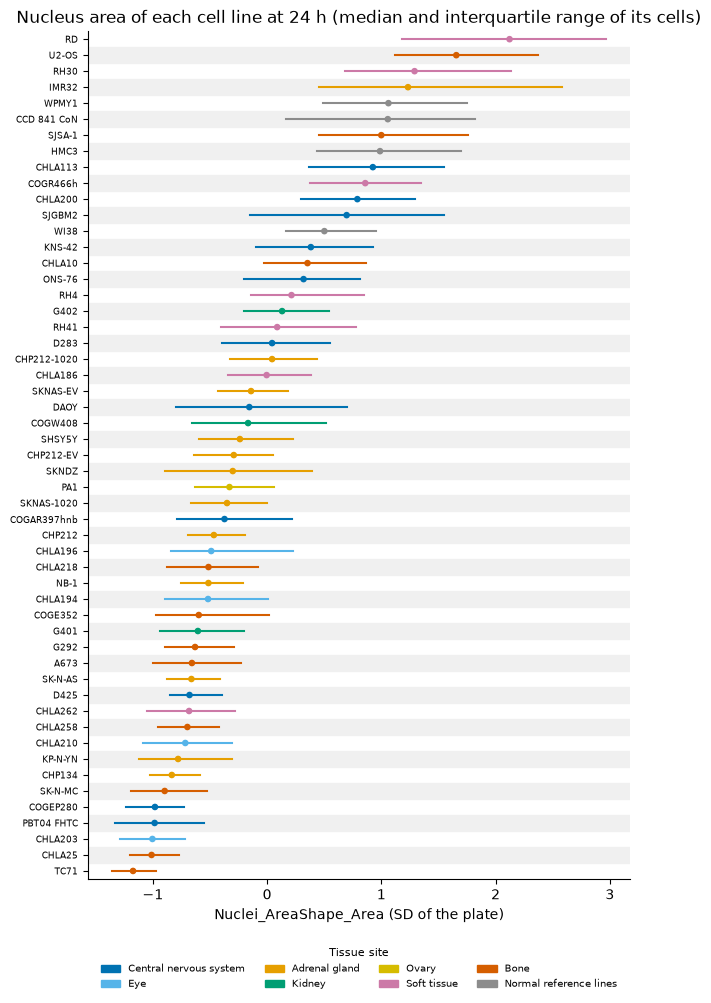

In [10]:
per_line = (
    size_df[size_df["time_point"] == 24].groupby(["cell_line", "tissue_site"], as_index=False)[["q25", "q50", "q75"]].median()
    .sort_values("q50", ascending=False).reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(7, 0.17 * len(per_line) + 2))
for row in per_line.index[1::2]:  # shade every other row to follow a cell line across to its value
    ax.axhspan(row - 0.5, row + 0.5, color="#F0F0F0", zorder=0)
for row in per_line.itertuples():
    ax.plot([row.q25, row.q75], [row.Index, row.Index], color=site_colors[row.tissue_site], lw=1.5)
ax.scatter(per_line["q50"], per_line.index, c=per_line["tissue_site"].map(site_colors), s=14, zorder=3)
ax.set_yticks(per_line.index, per_line["cell_line"], fontsize=6.5)
ax.set_ylim(len(per_line) - 0.5, -0.5)  # largest median on top
ax.set(title="Nucleus area of each cell line at 24 h (median and interquartile range of its cells)", xlabel="Nuclei_AreaShape_Area (SD of the plate)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(color=color, label=site) for site, color in site_colors.items() if site in set(per_line["tissue_site"])],
    title="Tissue site", ncol=4, fontsize=7, title_fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07),
)
plt.show()